# 02f Filtros de antigüedad: tamaño de la muestra y calidad del modelo

**Documento relacionado:** [`docs/03-analisis-exploratorio.md`](../docs/03-analisis-exploratorio.md) · **Acuerdo:** A-003 · **Decisiones:** D-002, [0003 Partición temporal](../docs/decisiones/0003-particion-temporal.md)

**Base:** [02a Antigüedad vs reseñas](02a_antiguedad_resenas.ipynb) (configuración y sesgo de exposición) y [02e Umbral mínimo de reseñas](02e_umbral_resenas_modelo.ipynb) (variables, modelos y diseño de la evaluación).

## Objetivo

Comparar cómo cambian la muestra y la calidad del modelo al quitar juegos según su año de lanzamiento. Se prueban las opciones que propuso el equipo el 2026-11-22 contra una **línea base sin quitar ningún año**:

| Escenario | Años que se conservan | Qué se elimina |
|---|---|---|
| **Base** | Todos | Nada |
| **Sin 2025–2026** | Hasta 2024 | Lanzamientos de 2025 y 2026 (D-002) |
| **Desde 2018** | 2018 en adelante | Lanzamientos anteriores a 2018 |
| **Desde 2019** | 2019 en adelante | Lanzamientos anteriores a 2019 |
| **Desde 2020** | 2020 en adelante | Lanzamientos anteriores a 2020 |

Como D-002 ya excluye 2025 y 2026, también se prueba cada corte inicial **combinado** con esa exclusión (2018–2024, 2019–2024 y 2020–2024).

| Entradas | Salidas |
|---|---|
| `steam_games.csv(.gz)` (versión 2026-11-19) | `reports/figures/02f_antiguedad_tamano.png`, `reports/figures/02f_antiguedad_modelo.png`, `reports/metrics/02f_antiguedad_*.csv` |

> [!warning] Alcance
> Es un experimento para decidir los filtros, no el modelo final. Las variables y la limpieza son las mismas versiones provisionales de 02e. El umbral mínimo de reseñas se fija en **50**, la propuesta de 02e para la decisión 0002, para que solo cambie el filtro de años. Puede cambiarse en `minReviews`.

## Configuración

Igual que en 02a y 02e, con los escenarios de este experimento.

In [1]:
from pathlib import Path
import os
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.ticker import FuncFormatter

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, roc_auc_score
from scipy.stats import spearmanr

# Rutas del repositorio (el notebook vive en notebooks/)
rootDir = Path('..').resolve()
figuresDir = rootDir / 'reports' / 'figures'
metricsDir = rootDir / 'reports' / 'metrics'
processedDir = rootDir / 'data' / 'processed'
interimDir = rootDir / 'data' / 'interim'
for outPath in (figuresDir, metricsDir, processedDir, interimDir):
    outPath.mkdir(parents=True, exist_ok=True)

# Datos: versión del 2026-11-19. Se busca primero la variable de entorno STEAM_GAMES_CSV,
# luego data/raw/ y por último la carpeta Proyecto Final/Datos (fuera del repositorio).
dataCandidates = [
    Path(os.environ['STEAM_GAMES_CSV']) if 'STEAM_GAMES_CSV' in os.environ else None,
    rootDir / 'data' / 'raw' / 'steam_games.csv.gz',
    rootDir / 'data' / 'raw' / 'steam_games.csv',
    rootDir.parents[1] / 'Datos' / 'steam_games.csv.gz',
]
dataPath = next((p for p in dataCandidates if p is not None and p.exists()), None)
if dataPath is None:
    raise FileNotFoundError('No se encontró steam_games.csv(.gz); colócalo en data/raw/ o define STEAM_GAMES_CSV')
print('Datos:', dataPath.name)

snapshotDate = pd.Timestamp('2026-11-19')   # fecha de corte de la versión del dataset

# Parámetros del experimento (A-003, filtros de antigüedad)
minReviews = 50                       # umbral mínimo de reseñas fijo (propuesta de 02e para la decisión 0002)
minMonthsInStore = 0                  # la línea base no quita juegos por antigüedad; cambiar para probar meses mínimos
commonYears = (2020, 2024)            # años presentes en todos los escenarios: prueba común
recentYears = (2025, 2026)
successCut = 0.80                     # «bien recibido»: >= 80 % positivas (umbral «Positive» de Steam)
seedList = [42, 7, 123, 2024, 31415]  # repeticiones de la partición aleatoria
testSize = 0.20
randomSeed = 42

# Escenarios: (primer año que se conserva, último año que se conserva); None = sin límite
scenarioDefs = {
    'Base (todos los años)': (None, None),
    'Sin 2025–2026': (None, 2024),
    'Desde 2018': (2018, None),
    'Desde 2019': (2019, None),
    'Desde 2020': (2020, None),
    '2018–2024': (2018, 2024),
    '2019–2024': (2019, 2024),
    '2020–2024': (2020, 2024),
}
scenarioList = list(scenarioDefs)
scenarioColors = {'Base (todos los años)': '#495057', 'Sin 2025–2026': '#ADB5BD',
                  'Desde 2018': '#74C0FC', 'Desde 2019': '#1C7ED6', 'Desde 2020': '#0B3D91',
                  '2018–2024': '#FFA94D', '2019–2024': '#F76707', '2020–2024': '#C92A2A'}

# Fuente latina + respaldo CJK (macOS: Hiragino/PingFang; Linux: Noto CJK). Solo las instaladas.
installedFonts = {f.name for f in fm.fontManager.ttflist}
cjkFonts = [f for f in ('Hiragino Sans GB', 'PingFang SC', 'Arial Unicode MS', 'Noto Sans CJK SC', 'Noto Sans CJK JP')
            if f in installedFonts]
plt.rcParams['font.family'] = ['DejaVu Sans'] + cjkFonts
pd.set_option('display.width', 200)

Datos: steam_games.csv


## Carga

Se lee con `keep_default_na=False, na_values=['']`, como indica el [diccionario de datos](../docs/02-diccionario-datos.md), y solo con las columnas que se usan.

In [2]:
useCols = ['app_id', 'name', 'release_date', 'price', 'price_status', 'positive', 'negative',
           'developers', 'publishers', 'genres', 'categories', 'supported_languages', 'full_audio_languages',
           'notes', 'achievements', 'mac', 'linux', 'screenshots', 'movies', 'website', 'support_url',
           'support_email', 'steam_store_available']
gamesDf = pd.read_csv(dataPath, low_memory=False, keep_default_na=False, na_values=[''], usecols=useCols)
print(f'{gamesDf.shape[0]:,} filas × {gamesDf.shape[1]} columnas leídas')

gamesDf['releaseDate'] = pd.to_datetime(gamesDf['release_date'], errors='coerce', format='mixed')
gamesDf['releaseYear'] = gamesDf['releaseDate'].dt.year
gamesDf['positive'] = pd.to_numeric(gamesDf['positive'], errors='coerce')
gamesDf['negative'] = pd.to_numeric(gamesDf['negative'], errors='coerce')
gamesDf['reviewCount'] = gamesDf['positive'] + gamesDf['negative']
gamesDf['positiveRatio'] = gamesDf['positive'] / gamesDf['reviewCount'].replace(0, np.nan)
gamesDf['ageYears'] = (snapshotDate - gamesDf['releaseDate']).dt.days / 365.25
gamesDf['price'] = pd.to_numeric(gamesDf['price'], errors='coerce')

150,199 filas × 23 columnas leídas


## Variables previas al lanzamiento (versión provisional)

Solo columnas con momento **Pre** o **Pre\*** del diccionario. Sin texto libre (D-007) y sin el nombre del desarrollador o del publisher (D-006, D-009): de ellos solo se usa su historial previo.

| Grupo | Variables |
|---|---|
| Precio | `logPrice`, `isFree`, `priceUnavailable` (Pre\*: precio al 2026-11-19) |
| Fecha | `releaseYear` (control de cohorte), `releaseMonth` |
| Plataformas | `mac`, `linux` (`windows` es casi constante) |
| Idiomas | `nLanguages`, `nFullAudio` |
| Tienda | `logAchievements`, `nScreenshots`, `nMovies` (Pre\*), `hasWebsite`, `hasSupportUrl`, `hasSupportEmail`, `hasMatureNotice` |
| Géneros | Indicadores de géneros oficiales en inglés, incluidas las etiquetas comerciales Indie, Early Access y Free To Play (D-005 las separa; aquí entran como indicadores) |
| Categorías | Indicadores de las 30 categorías más frecuentes, sin Steam Trading Cards (Post) |
| Desarrollador y publisher | `logDevPrior`, `logPubPrior`: juegos que lanzó antes, contados con todo el catálogo y solo con fechas anteriores (A-004, sin fuga); `selfPublished` |

Son las mismas variables de [02e](02e_umbral_resenas_modelo.ipynb). `releaseYear` entra como control de cohorte: el modelo puede ajustar la tendencia de la proporción positiva entre años.

In [3]:
def parseJsonList(rawValue):
    # Lista JSON de textos u objetos {"id", "description"}; devuelve lista de textos.
    if not isinstance(rawValue, str) or not rawValue.startswith('['):
        return []
    try:
        items = json.loads(rawValue)
    except json.JSONDecodeError:
        return []
    return [str(it.get('description', '')).strip() if isinstance(it, dict) else str(it).strip() for it in items]


def countLanguages(rawValue):
    # supported_languages viene como lista JSON o como texto HTML («English<strong>*</strong>, French<br>...»).
    if not isinstance(rawValue, str) or rawValue.strip() in ('', '[]'):
        return 0
    if rawValue.startswith('['):
        return len([x for x in parseJsonList(rawValue) if x])
    cleanText = re.sub(r'<br>.*$', '', rawValue, flags=re.S)
    cleanText = re.sub(r'<[^>]+>|\*', '', cleanText)
    return len([x for x in cleanText.split(',') if x.strip()])


def countJsonItems(rawValue):
    if not isinstance(rawValue, str) or not rawValue.startswith('['):
        return 0
    try:
        return len(json.loads(rawValue))
    except json.JSONDecodeError:
        return 0


def hasText(series):
    return series.fillna('').astype(str).str.strip().str.len().gt(3).astype(int)


genreLists = gamesDf['genres'].map(parseJsonList)
categoryLists = gamesDf['categories'].map(parseJsonList)
devLists = gamesDf['developers'].map(lambda v: [x.lower() for x in parseJsonList(v) if x])
pubLists = gamesDf['publishers'].map(lambda v: [x.lower() for x in parseJsonList(v) if x])

featDf = pd.DataFrame(index=gamesDf.index)
featDf['logPrice'] = np.log1p(gamesDf['price'].clip(upper=200)).fillna(0)
featDf['priceUnavailable'] = gamesDf['price'].isna().astype(int)
featDf['isFree'] = (gamesDf['price_status'] == 'free').astype(int)
featDf['releaseYear'] = gamesDf['releaseYear']
featDf['releaseMonth'] = gamesDf['releaseDate'].dt.month
featDf['mac'] = (gamesDf['mac'].astype(str) == 'True').astype(int)
featDf['linux'] = (gamesDf['linux'].astype(str) == 'True').astype(int)
featDf['nLanguages'] = gamesDf['supported_languages'].map(countLanguages)
featDf['nFullAudio'] = gamesDf['full_audio_languages'].map(countJsonItems)
featDf['logAchievements'] = np.log1p(pd.to_numeric(gamesDf['achievements'], errors='coerce').fillna(0).clip(upper=5000))
featDf['nScreenshots'] = gamesDf['screenshots'].map(countJsonItems)
featDf['nMovies'] = gamesDf['movies'].map(countJsonItems)
featDf['hasWebsite'] = hasText(gamesDf['website'])
featDf['hasSupportUrl'] = hasText(gamesDf['support_url'])
featDf['hasSupportEmail'] = hasText(gamesDf['support_email'])
featDf['hasMatureNotice'] = hasText(gamesDf['notes'])
featDf['selfPublished'] = [int(bool(set(d) & set(p))) for d, p in zip(devLists, pubLists)]

# Géneros oficiales en inglés (los traducidos aparecen 1 o 2 veces y se ignoran)
genreList = ['Indie', 'Casual', 'Action', 'Adventure', 'Simulation', 'Strategy', 'RPG', 'Free To Play',
             'Early Access', 'Sports', 'Racing', 'Massively Multiplayer', 'Violent', 'Gore', 'Nudity', 'Sexual Content']
for genreName in genreList:
    featDf['g_' + re.sub(r'\W+', '', genreName)] = genreLists.map(lambda gs: int(genreName in gs))

# Categorías más frecuentes, sin Steam Trading Cards (Steam la activa por ventas: fuga)
categoryCounts = categoryLists.explode().value_counts()
categoryCounts = categoryCounts[~categoryCounts.index.isin(['', 'Steam Trading Cards']) &
                                ~categoryCounts.index.astype(str).str.startswith('#')]
categoryList = categoryCounts.head(30).index.tolist()
for categoryName in categoryList:
    featDf['c_' + re.sub(r'\W+', '', categoryName)] = categoryLists.map(lambda cs: int(categoryName in cs))


def priorReleaseCount(entityLists):
    # Juegos del mismo desarrollador/publisher lanzados ANTES de cada juego (mismas fechas no cuentan).
    longDf = pd.DataFrame({'row': gamesDf.index, 'entity': entityLists, 'date': gamesDf['releaseDate']})
    longDf = longDf.explode('entity').dropna(subset=['entity', 'date']).sort_values(['entity', 'date'])
    longDf['prior'] = longDf.groupby('entity').cumcount()
    longDf['prior'] = longDf.groupby(['entity', 'date'])['prior'].transform('min')
    return longDf.groupby('row')['prior'].max().reindex(gamesDf.index).fillna(0)


featDf['logDevPrior'] = np.log1p(priorReleaseCount(devLists))
featDf['logPubPrior'] = np.log1p(priorReleaseCount(pubLists))
featureCols = list(featDf.columns)
print(f'{len(featureCols)} variables:', ', '.join(featureCols[:16]), '…')

65 variables: logPrice, priceUnavailable, isFree, releaseYear, releaseMonth, mac, linux, nLanguages, nFullAudio, logAchievements, nScreenshots, nMovies, hasWebsite, hasSupportUrl, hasSupportEmail, hasMatureNotice …


## Universo de modelado

A diferencia de 02e, aquí **no** se filtra por años ni por meses en tienda: eso es lo que se compara. Solo se aplica la limpieza mínima provisional de 02e:

- fecha de lanzamiento válida (hasta la fecha de corte);
- sin el precio atípico de 107,500 dólares (D-004) y con datos de tienda;
- solo juegos (D-005, provisional): sin aplicaciones de software ni nombres de Soundtrack, Demo, Playtest, SDK o Dedicated Server;
- al menos `minReviews` reseñas (50).

In [4]:
softwareGenres = {'Utilities', 'Design & Illustration', 'Animation & Modeling', 'Education', 'Video Production',
                  'Game Development', 'Audio Production', 'Software Training', 'Photo Editing', 'Web Publishing',
                  'Accounting', 'Movie', 'Documentary', 'Episodic', 'Short', 'Tutorial', '360 Video'}
onlySoftware = genreLists.map(lambda gs: len(gs) > 0 and set(gs) <= softwareGenres)
nonGameName = gamesDf['name'].fillna('').str.contains(r'\b(?:soundtrack|OST|demo|playtest|SDK|dedicated server)\b',
                                                      case=False, regex=True)

filterSteps = [
    ('Catálogo completo', pd.Series(True, index=gamesDf.index)),
    ('Fecha válida (≤ fecha de corte)', gamesDf['releaseDate'].notna() & (gamesDf['releaseDate'] <= snapshotDate)),
    (f'≥ {minMonthsInStore} meses en tienda', gamesDf['releaseDate'] <= snapshotDate - pd.DateOffset(months=minMonthsInStore)),
    ('Sin precio atípico (D-004) y con datos de tienda', (gamesDf['price'].fillna(0) < 1000)
                                                        & (gamesDf['steam_store_available'].astype(str) == 'True')),
    ('Solo juegos (D-005, provisional)', ~onlySoftware & ~nonGameName),
    (f'≥ {minReviews} reseñas', gamesDf['reviewCount'] >= minReviews),
]
keepMask = pd.Series(True, index=gamesDf.index)
funnelRows = []
for stepName, stepMask in filterSteps:
    keepMask &= stepMask
    funnelRows.append({'paso': stepName, 'juegos': int(keepMask.sum())})
display(pd.DataFrame(funnelRows))

universeDf = pd.concat([gamesDf.loc[keepMask, ['app_id', 'name', 'releaseDate', 'releaseYear', 'ageYears',
                                               'reviewCount', 'positiveRatio']],
                        featDf.loc[keepMask].drop(columns='releaseYear')], axis=1).reset_index(drop=True)
universeDf['releaseYear'] = universeDf['releaseYear'].astype(int)
print(f'Universo (línea base): {len(universeDf):,} juegos, '
      f'{universeDf["releaseYear"].min()}–{universeDf["releaseYear"].max()}')


def scenarioMask(df, scenarioName):
    firstYear, lastYear = scenarioDefs[scenarioName]
    mask = pd.Series(True, index=df.index)
    if firstYear is not None:
        mask &= df['releaseYear'] >= firstYear
    if lastYear is not None:
        mask &= df['releaseYear'] <= lastYear
    return mask

,paso,juegos
0,Catálogo completo,150199
1,Fecha válida (≤ fecha de corte),150117
2,≥ 0 meses en tienda,150117
3,Sin precio atípico (D-004) y con datos de tienda,150113
4,"Solo juegos (D-005, provisional)",140699
5,≥ 50 reseñas,30407


Universo (línea base): 30,407 juegos, 1997–2026


## 1. Impacto en el tamaño y la composición del dataset

Para cada escenario se mide cuántos juegos quedan y cómo cambia su composición: antigüedad, peso de los años recientes y distribución de la proporción positiva.

La **deriva entre cohortes** es el rango de las medianas anuales de la proporción positiva dentro del escenario. En [02_eda](02_eda.ipynb) la mediana subía de 0.74 en 2014 a 0.88 en 2024. Cuanto mayor es la deriva, más depende el modelo de `releaseYear` para no confundir «reciente» con «mejor valorado».

La **confiabilidad** se calcula igual que en 02e: \(1 - \overline{\hat p(1-\hat p)/n} / \operatorname{Var}(\hat p)\).

In [5]:
baseN = len(universeDf)
sizeRows = []
for scenarioName in scenarioList:
    keptDf = universeDf[scenarioMask(universeDf, scenarioName)]
    ratio = keptDf['positiveRatio']
    noiseVar = (ratio * (1 - ratio) / keptDf['reviewCount']).mean()
    yearMedian = keptDf.groupby('releaseYear')['positiveRatio'].median()
    yearCounts = keptDf['releaseYear'].value_counts()
    yearMedian = yearMedian[yearCounts.reindex(yearMedian.index) >= 30]
    sizeRows.append({
        'escenario': scenarioName,
        'anios': f"{keptDf['releaseYear'].min()}–{keptDf['releaseYear'].max()}",
        'juegos': len(keptDf),
        'pctBase': len(keptDf) / baseN * 100,
        'juegosEliminados': baseN - len(keptDf),
        'medianaAntiguedad': keptDf['ageYears'].median(),
        'pctAntes2018': (keptDf['releaseYear'] < 2018).mean() * 100,
        'pct2025a2026': keptDf['releaseYear'].between(*recentYears).mean() * 100,
        'medianaResenas': keptDf['reviewCount'].median(),
        'pctAutopublicados': keptDf['selfPublished'].mean() * 100,
        'mediaRatio': ratio.mean(),
        'medianaRatio': ratio.median(),
        'desvRatio': ratio.std(),
        'pctBienRecibidos': (ratio >= successCut).mean() * 100,
        'derivaCohortes': yearMedian.max() - yearMedian.min(),
        'confiabilidad': 1 - noiseVar / ratio.var(),
    })
sizeDf = pd.DataFrame(sizeRows)
sizeDf.to_csv(metricsDir / '02f_antiguedad_tamano.csv', index=False)
sizeDf.round(3)

,escenario,anios,juegos,pctBase,juegosEliminados,medianaAntiguedad,pctAntes2018,pct2025a2026,medianaResenas,pctAutopublicados,mediaRatio,medianaRatio,desvRatio,pctBienRecibidos,derivaCohortes,confiabilidad
0,Base (todos los años),1997–2026,30407,100.000,0,6.938,33.621,5.413,240.0,63.739,0.785,0.820,0.155,55.132,0.124,0.961
1,Sin 2025–2026,1997–2024,28761,94.587,1646,7.253,35.545,0.000,241.0,63.579,0.782,0.817,0.156,54.271,0.124,0.961
2,Desde 2018,2018–2026,20184,66.379,10223,4.980,0.000,8.155,211.0,66.037,0.808,0.841,0.142,60.716,0.085,0.954
3,Desde 2019,2019–2026,17505,57.569,12902,4.392,0.000,9.403,215.0,65.547,0.816,0.848,0.137,62.719,0.048,0.953
4,Desde 2020,2020–2026,15115,49.709,15292,3.945,0.000,10.890,214.0,65.273,0.820,0.852,0.135,63.678,0.036,0.952
5,2018–2024,2018–2024,18538,60.966,11869,5.273,0.000,0.000,210.0,65.994,0.805,0.838,0.143,59.877,0.076,0.954
6,2019–2024,2019–2024,15859,52.156,14548,4.742,0.000,0.000,214.0,65.445,0.813,0.845,0.138,61.946,0.038,0.953
7,2020–2024,2020–2024,13469,44.296,16938,4.235,0.000,0.000,212.0,65.120,0.818,0.849,0.136,62.885,0.026,0.952


### Juegos y proporción positiva por año de lanzamiento

Cuántos juegos con ≥ 50 reseñas aporta cada año y su mediana de proporción positiva. Los años de 2025 y 2026 solo incluyen los juegos que ya juntaron 50 reseñas, un subconjunto de los más exitosos de esos años.

In [6]:
yearProfile = (universeDf.groupby('releaseYear')
               .agg(juegos=('app_id', 'size'), medianaRatio=('positiveRatio', 'median'),
                    mediaRatio=('positiveRatio', 'mean'), pctBienRecibidos=('positiveRatio', lambda s: (s >= successCut).mean() * 100),
                    medianaAntiguedad=('ageYears', 'median'))
               .reset_index())
yearProfile['pctDelTotal'] = yearProfile['juegos'] / baseN * 100
yearProfile.to_csv(metricsDir / '02f_antiguedad_por_anio.csv', index=False)
yearProfile[yearProfile['releaseYear'] >= 2006].round(3)

,releaseYear,juegos,medianaRatio,mediaRatio,pctBienRecibidos,medianaAntiguedad,pctDelTotal
9,2006,64,0.874,0.846,70.312,20.185,0.210
10,2007,87,0.860,0.816,63.218,19.381,0.286
11,2008,138,0.841,0.792,63.043,18.308,0.454
12,2009,265,0.825,0.786,56.226,17.325,0.872
13,2010,214,0.811,0.760,52.804,16.337,0.704
14,2011,238,0.781,0.744,46.639,15.299,0.783
15,2012,306,0.808,0.761,52.288,14.290,1.006
16,2013,446,0.791,0.753,47.534,13.164,1.467
17,2014,1358,0.751,0.713,38.881,12.379,4.466
18,2015,1886,0.754,0.722,38.918,11.343,6.203


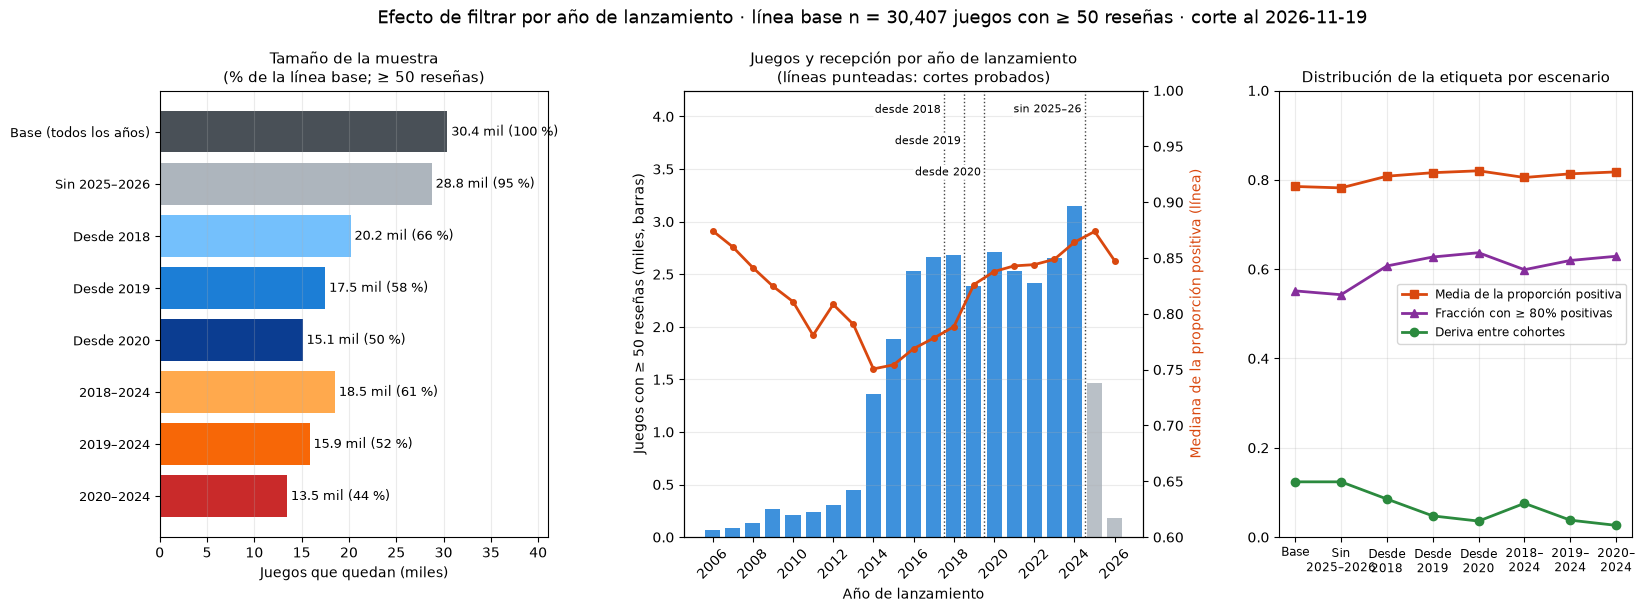

In [7]:
fig, (axSize, axYear, axDist) = plt.subplots(1, 3, figsize=(19, 5.8), gridspec_kw={'wspace': 0.34, 'width_ratios': [1.1, 1.3, 1]})

yPos = np.arange(len(scenarioList))[::-1]
axSize.barh(yPos, sizeDf['juegos'] / 1000, color=[scenarioColors[s] for s in scenarioList])
for y, (n, pct) in zip(yPos, zip(sizeDf['juegos'], sizeDf['pctBase'])):
    axSize.text(n / 1000 + 0.4, y, f'{n/1000:.1f} mil ({pct:.0f} %)', va='center', fontsize=9)
axSize.set_yticks(yPos)
axSize.set_yticklabels(scenarioList, fontsize=9.5)
axSize.set_xlim(0, sizeDf['juegos'].max() / 1000 * 1.35)
axSize.set_xlabel('Juegos que quedan (miles)')
axSize.set_title(f'Tamaño de la muestra\n(% de la línea base; ≥ {minReviews} reseñas)', fontsize=11)
axSize.grid(axis='x', alpha=0.25)

plotYears = yearProfile[yearProfile['releaseYear'] >= 2006]
axYear.bar(plotYears['releaseYear'], plotYears['juegos'] / 1000,
           color=['#ADB5BD' if y >= 2025 else '#1C7ED6' for y in plotYears['releaseYear']], alpha=0.85, width=0.75)
axYear.set_ylabel('Juegos con ≥ 50 reseñas (miles, barras)')
axYear.set_xlabel('Año de lanzamiento')
axYear.set_xticks(plotYears['releaseYear'][::2])
axYear.tick_params(axis='x', rotation=45)
axYear.set_ylim(0, plotYears['juegos'].max() / 1000 * 1.35)
for (cutYear, cutLabel), yFrac in zip([(2017.5, 'desde 2018'), (2018.5, 'desde 2019'), (2019.5, 'desde 2020'),
                                       (2024.5, 'sin 2025–26')], [0.97, 0.90, 0.83, 0.97]):
    axYear.axvline(cutYear, color='#444', lw=1, ls=':')
    axYear.text(cutYear - 0.15, axYear.get_ylim()[1] * yFrac, cutLabel, fontsize=8, ha='right', va='top',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'))
axYear.grid(axis='y', alpha=0.25)
axRatio = axYear.twinx()
axRatio.plot(plotYears['releaseYear'], plotYears['medianaRatio'], color='#D9480F', marker='o', ms=4, lw=2)
axRatio.set_ylim(0.6, 1.0)
axRatio.set_ylabel('Mediana de la proporción positiva (línea)', color='#D9480F')
axYear.set_title('Juegos y recepción por año de lanzamiento\n(líneas punteadas: cortes probados)', fontsize=11)

xPos = np.arange(len(scenarioList))
axDist.plot(xPos, sizeDf['mediaRatio'], color='#D9480F', marker='s', lw=2, label='Media de la proporción positiva')
axDist.plot(xPos, sizeDf['pctBienRecibidos'] / 100, color='#862E9C', marker='^', lw=2,
            label=f'Fracción con ≥ {successCut:.0%} positivas')
axDist.plot(xPos, sizeDf['derivaCohortes'], color='#2B8A3E', marker='o', lw=2, label='Deriva entre cohortes')
axDist.set_xticks(xPos)
axDist.set_xticklabels([s.replace(' (todos los años)', '').replace('Sin ', 'Sin\n').replace('Desde ', 'Desde\n')
                        .replace('–2024', '–\n2024') for s in scenarioList], fontsize=8.5)
axDist.set_ylim(0, 1)
axDist.set_title('Distribución de la etiqueta por escenario', fontsize=11)
axDist.legend(fontsize=8.5, loc='center right')
axDist.grid(alpha=0.25)

fig.suptitle(f'Efecto de filtrar por año de lanzamiento · línea base n = {baseN:,} juegos con ≥ {minReviews} reseñas · '
             f'corte al {snapshotDate.date()}', fontsize=13, y=1.02)
fig.savefig(figuresDir / '02f_antiguedad_tamano.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Impacto en la calidad del modelo

### Diseño del experimento

Igual que en 02e, comparar cada escenario solo con su propio conjunto de prueba es engañoso: cada uno se probaría con juegos distintos, de años con recepciones distintas. Por eso cada modelo se evalúa de cinco formas:

| Evaluación | Entrenamiento | Prueba | Qué responde |
|---|---|---|---|
| **Propia** | Juegos del escenario | Juegos de prueba del escenario | Qué tan bien se ve el modelo dentro de la muestra que define el filtro |
| **Común (2020–2024)** | Juegos del escenario | Los mismos juegos de prueba de 2020–2024 en todos los escenarios | Si quitar o conservar años ayuda a predecir juegos recientes con historial completo |
| **Mismo tamaño** | Submuestra del escenario del tamaño de «2020–2024» | Común (2020–2024) | Si la diferencia viene del número de juegos o de qué años se usan |
| **Recientes (2025–2026)** | Juegos del escenario | Juegos de prueba de 2025–2026 con ≥ 50 reseñas | Qué tan bien se predicen los lanzamientos más nuevos, incluso si se excluyen del entrenamiento |
| **Temporal** | Juegos del escenario lanzados hasta 2022 | Juegos de 2023–2024 | Predecir cohortes futuras, como se usaría el modelo |

La partición aleatoria (80/20, 5 semillas) se hace una vez por semilla sobre la línea base, así que un juego de prueba nunca entra al entrenamiento de ningún escenario. En la evaluación temporal los escenarios que solo difieren en 2025–2026 son idénticos, porque esos años nunca se usan para entrenar.

Los modelos y las métricas son los de 02e: media por cohorte, Ridge y gradient boosting. Se miden \(R^2\), MAE, RMSE, Spearman y AUC para los juegos con ≥ 80 % positivas.

In [8]:
def makeModels(seed):
    return {
        'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        'Gradient boosting': HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                                           min_samples_leaf=40, l2_regularization=1.0,
                                                           early_stopping=True, validation_fraction=0.1,
                                                           random_state=seed),
    }


def scorePredictions(yTrue, yPred):
    yPred = np.clip(yPred, 0, 1)
    isSuccess = (yTrue >= successCut).astype(int)
    return {
        'r2': r2_score(yTrue, yPred),
        'mae': mean_absolute_error(yTrue, yPred),
        'rmse': mean_squared_error(yTrue, yPred) ** 0.5,
        'spearman': spearmanr(yTrue, yPred).statistic if np.ptp(yPred) > 1e-9 else np.nan,
        'auc': roc_auc_score(isSuccess, yPred) if len(np.unique(isSuccess)) == 2 else np.nan,
    }


def evaluateThreshold(trainDf, evalSets, seed, label):
    # Entrena los modelos con trainDf y los evalúa en cada conjunto de evalSets.
    rows = []
    cohortMean = trainDf.groupby('releaseYear')['positiveRatio'].mean()
    latestMean = cohortMean.iloc[-1]   # cohortes sin datos de entrenamiento (partición temporal): la más reciente
    fittedModels = {name: model.fit(trainDf[featureCols], trainDf['positiveRatio'])
                    for name, model in makeModels(seed).items()}
    for evalName, evalDf in evalSets.items():
        predictions = {'Base por cohorte': evalDf['releaseYear'].map(cohortMean).fillna(latestMean).to_numpy()}
        predictions.update({name: model.predict(evalDf[featureCols]) for name, model in fittedModels.items()})
        for modelName, yPred in predictions.items():
            rows.append({'esquema': label, 'evaluacion': evalName, 'modelo': modelName, 'semilla': seed,
                         'nEntrenamiento': len(trainDf), 'nPrueba': len(evalDf),
                         **scorePredictions(evalDf['positiveRatio'].to_numpy(), yPred)})
    return rows

### Partición aleatoria repetida

In [9]:
commonMask = universeDf['releaseYear'].between(*commonYears)
recentMask = universeDf['releaseYear'].between(*recentYears)
resultRows = []
for seed in seedList:
    trainIdx, testIdx = train_test_split(universeDf.index, test_size=testSize, random_state=seed)
    trainPool, testPool = universeDf.loc[trainIdx], universeDf.loc[testIdx]
    commonTest = testPool[commonMask.loc[testIdx]]
    recentTest = testPool[recentMask.loc[testIdx]]
    sameSizeN = int(scenarioMask(trainPool, '2020–2024').sum())
    for scenarioName in scenarioList:
        trainDf = trainPool[scenarioMask(trainPool, scenarioName)]
        ownTest = testPool[scenarioMask(testPool, scenarioName)]
        resultRows += evaluateThreshold(trainDf, {'Propia': ownTest, 'Común (2020–2024)': commonTest,
                                                  'Recientes (2025–2026)': recentTest}, seed, scenarioName)
        sameSizeDf = trainDf.sample(n=min(sameSizeN, len(trainDf)), random_state=seed)
        resultRows += evaluateThreshold(sameSizeDf, {'Común, mismo tamaño': commonTest}, seed, scenarioName)
    print(f'Semilla {seed}: listo')

resultsDf = pd.DataFrame(resultRows).rename(columns={'esquema': 'escenario'})
resultsDf.to_csv(metricsDir / '02f_antiguedad_modelo_detalle.csv', index=False)

Semilla 42: listo


Semilla 7: listo


Semilla 123: listo


Semilla 2024: listo


Semilla 31415: listo


### Comprobación con partición temporal

In [10]:
temporalRows = []
trainPoolT = universeDf[universeDf['releaseYear'] <= 2022]
testPoolT = universeDf[universeDf['releaseYear'].between(2023, 2024)]
for scenarioName in scenarioList:
    trainDf = trainPoolT[scenarioMask(trainPoolT, scenarioName)]
    temporalRows += evaluateThreshold(trainDf, {'Temporal (2023–2024)': testPoolT}, randomSeed, scenarioName)
temporalDf = pd.DataFrame(temporalRows).rename(columns={'esquema': 'escenario'})
temporalDf.to_csv(metricsDir / '02f_antiguedad_modelo_temporal.csv', index=False)

metricCols = ['r2', 'mae', 'rmse', 'spearman', 'auc']
allResults = pd.concat([resultsDf, temporalDf], ignore_index=True)
summaryDf = (allResults.groupby(['evaluacion', 'modelo', 'escenario'])
             .agg(nEntrenamiento=('nEntrenamiento', 'mean'), nPrueba=('nPrueba', 'mean'),
                  **{m: (m, 'mean') for m in metricCols}, r2Desv=('r2', 'std'))
             .reset_index())
summaryDf['r2Desv'] = summaryDf['r2Desv'].fillna(0)   # la temporal tiene una sola corrida
summaryDf.to_csv(metricsDir / '02f_antiguedad_modelo_resumen.csv', index=False)

### Resultados: gradient boosting

Media de las 5 semillas (la temporal es una sola corrida); `r2Desv` es la desviación estándar del \(R^2\) entre semillas.

In [11]:
evalOrder = ['Propia', 'Común (2020–2024)', 'Común, mismo tamaño', 'Recientes (2025–2026)', 'Temporal (2023–2024)']
gbTable = (summaryDf[summaryDf['modelo'] == 'Gradient boosting']
           .assign(evaluacion=lambda d: pd.Categorical(d['evaluacion'], evalOrder, ordered=True),
                   escenario=lambda d: pd.Categorical(d['escenario'], scenarioList, ordered=True))
           .sort_values(['evaluacion', 'escenario'])
           .drop(columns='modelo'))
gbTable.round(3)

,evaluacion,escenario,nEntrenamiento,nPrueba,r2,mae,rmse,spearman,auc,r2Desv
59,Propia,Base (todos los años),24325.0,6082.0,0.267,0.102,0.132,0.509,0.747,0.006
63,Propia,Sin 2025–2026,23006.8,5754.2,0.264,0.103,0.133,0.507,0.746,0.007
60,Propia,Desde 2018,16168.8,4015.2,0.233,0.095,0.123,0.477,0.735,0.008
61,Propia,Desde 2019,14014.0,3491.0,0.209,0.093,0.121,0.462,0.729,0.013
62,Propia,Desde 2020,12087.2,3027.8,0.203,0.092,0.119,0.460,0.727,0.020
56,Propia,2018–2024,14850.6,3687.4,0.231,0.096,0.124,0.475,0.735,0.014
57,Propia,2019–2024,12695.8,3163.2,0.206,0.094,0.122,0.460,0.730,0.017
58,Propia,2020–2024,10769.0,2700.0,0.201,0.093,0.120,0.462,0.730,0.017
11,Común (2020–2024),Base (todos los años),24325.0,2700.0,0.202,0.093,0.120,0.461,0.729,0.016
15,Común (2020–2024),Sin 2025–2026,23006.8,2700.0,0.205,0.092,0.120,0.464,0.731,0.017


### Comparación de modelos

\(R^2\) medio por modelo y escenario en la prueba común (2020–2024).

In [12]:
modelPivot = (summaryDf[summaryDf['evaluacion'] == 'Común (2020–2024)']
              .pivot(index='modelo', columns='escenario', values='r2')
              .reindex(index=['Base por cohorte', 'Ridge', 'Gradient boosting'], columns=scenarioList))
modelPivot.round(3)

escenario,Base (todos los años),Sin 2025–2026,Desde 2018,Desde 2019,Desde 2020,2018–2024,2019–2024,2020–2024
modelo,,,,,,,,
Base por cohorte,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003
Ridge,0.105,0.100,0.141,0.149,0.150,0.140,0.149,0.150
Gradient boosting,0.202,0.205,0.206,0.206,0.200,0.206,0.205,0.201


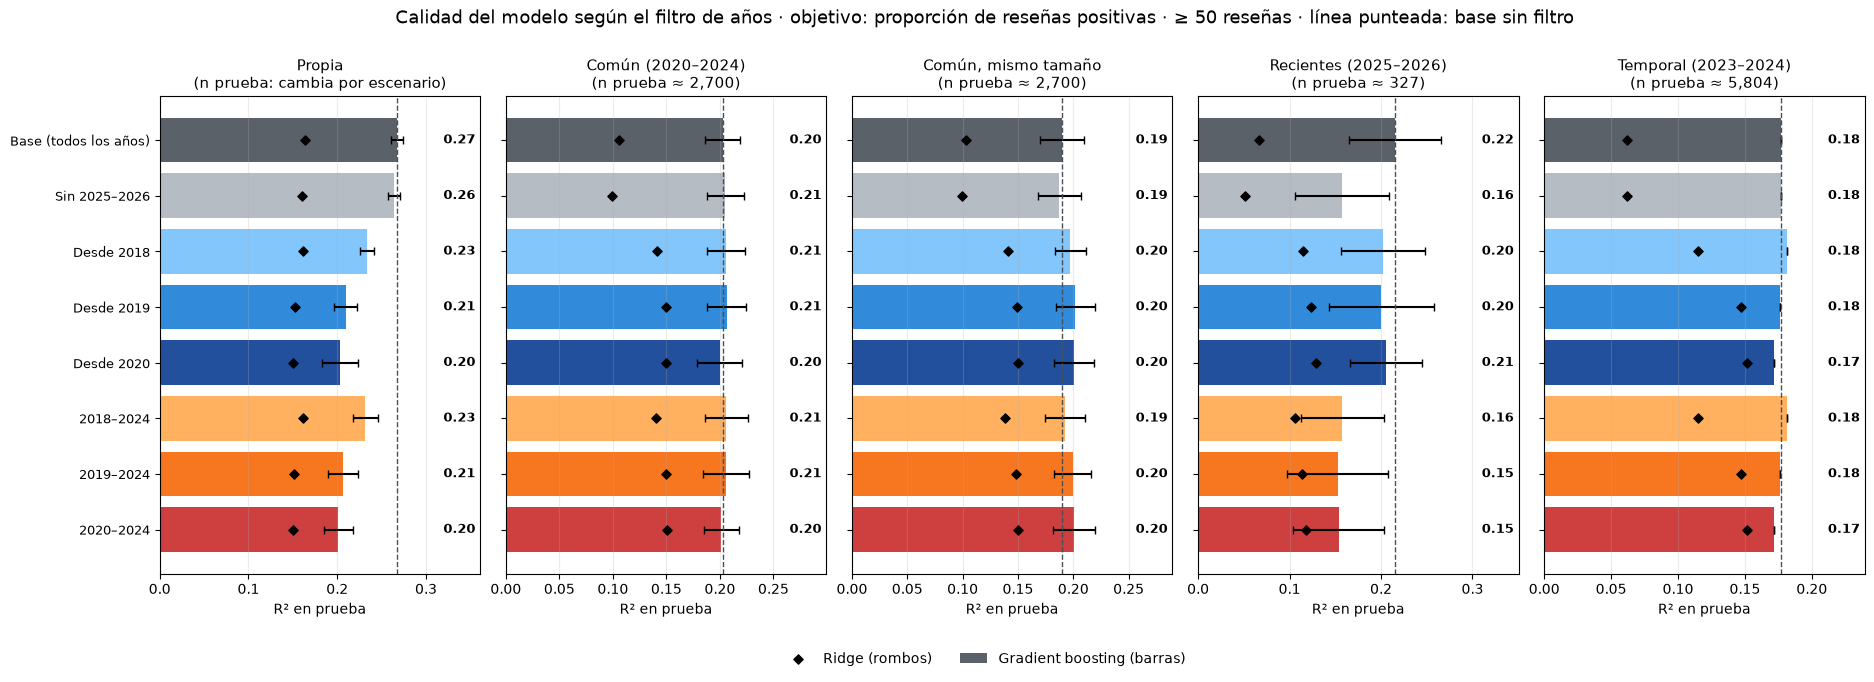

In [13]:
plotEvals = ['Propia', 'Común (2020–2024)', 'Común, mismo tamaño', 'Recientes (2025–2026)', 'Temporal (2023–2024)']
fig, axList = plt.subplots(1, len(plotEvals), figsize=(22, 6.2), sharey=True, gridspec_kw={'wspace': 0.08})
yPos = np.arange(len(scenarioList))[::-1]
for axCur, evalName in zip(axList, plotEvals):
    gbSub = summaryDf[(summaryDf['evaluacion'] == evalName) & (summaryDf['modelo'] == 'Gradient boosting')] \
        .set_index('escenario').reindex(scenarioList)
    ridgeSub = summaryDf[(summaryDf['evaluacion'] == evalName) & (summaryDf['modelo'] == 'Ridge')] \
        .set_index('escenario').reindex(scenarioList)
    axCur.barh(yPos, gbSub['r2'], xerr=gbSub['r2Desv'], color=[scenarioColors[s] for s in scenarioList],
               alpha=0.9, capsize=3, label='Gradient boosting (barras)')
    axCur.scatter(ridgeSub['r2'], yPos, color='black', marker='D', s=22, zorder=3, label='Ridge (rombos)')
    xRight = max(np.nanmax(gbSub['r2'] + gbSub['r2Desv']) * 1.32, 0.1)
    for y, val in zip(yPos, gbSub['r2']):
        axCur.text(xRight * 0.985, y, f'{val:.2f}', va='center', ha='right', fontsize=9, fontweight='bold')
    baseVal = gbSub.loc['Base (todos los años)', 'r2']
    axCur.axvline(baseVal, color='#495057', lw=1, ls='--')
    nTestText = f"n prueba ≈ {int(gbSub['nPrueba'].mean()):,}" if evalName != 'Propia' else 'n prueba: cambia por escenario'
    axCur.set_title(f'{evalName}\n({nTestText})', fontsize=10.5)
    axCur.set_xlim(min(0, np.nanmin(ridgeSub['r2']) - 0.02), xRight)
    axCur.set_xlabel('R² en prueba')
    axCur.grid(axis='x', alpha=0.25)
axList[0].set_yticks(yPos)
axList[0].set_yticklabels(scenarioList, fontsize=9.5)
handles, labels = axList[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=10, bbox_to_anchor=(0.5, -0.06), frameon=False)
fig.suptitle(f'Calidad del modelo según el filtro de años · objetivo: proporción de reseñas positivas · '
             f'≥ {minReviews} reseñas · línea punteada: base sin filtro', fontsize=13, y=1.02)
fig.savefig(figuresDir / '02f_antiguedad_modelo.png', dpi=150, bbox_inches='tight')
plt.show()

## Resumen para la decisión 0003 y D-002

In [14]:
gbSummary = summaryDf[summaryDf['modelo'] == 'Gradient boosting']
decisionDf = sizeDf[['escenario', 'anios', 'juegos', 'pctBase', 'derivaCohortes', 'pctBienRecibidos']].copy()
for evalName, colName in [('Propia', 'r2Propia'), ('Común (2020–2024)', 'r2Comun'), ('Común, mismo tamaño', 'r2MismoTamano'),
                          ('Recientes (2025–2026)', 'r2Recientes'), ('Temporal (2023–2024)', 'r2Temporal')]:
    decisionDf[colName] = decisionDf['escenario'].map(gbSummary[gbSummary['evaluacion'] == evalName].set_index('escenario')['r2'])
decisionDf['aucComun'] = decisionDf['escenario'].map(
    gbSummary[gbSummary['evaluacion'] == 'Común (2020–2024)'].set_index('escenario')['auc'])
decisionDf.to_csv(metricsDir / '02f_antiguedad_decision.csv', index=False)
decisionDf.round(3)

,escenario,anios,juegos,pctBase,derivaCohortes,pctBienRecibidos,r2Propia,r2Comun,r2MismoTamano,r2Recientes,r2Temporal,aucComun
0,Base (todos los años),1997–2026,30407,100.000,0.124,55.132,0.267,0.202,0.190,0.215,0.177,0.729
1,Sin 2025–2026,1997–2024,28761,94.587,0.124,54.271,0.264,0.205,0.187,0.157,0.177,0.731
2,Desde 2018,2018–2026,20184,66.379,0.085,60.716,0.233,0.206,0.197,0.202,0.181,0.731
3,Desde 2019,2019–2026,17505,57.569,0.048,62.719,0.209,0.206,0.202,0.200,0.176,0.731
4,Desde 2020,2020–2026,15115,49.709,0.036,63.678,0.203,0.200,0.200,0.206,0.172,0.727
5,2018–2024,2018–2024,18538,60.966,0.076,59.877,0.231,0.206,0.192,0.158,0.181,0.731
6,2019–2024,2019–2024,15859,52.156,0.038,61.946,0.206,0.205,0.199,0.153,0.176,0.731
7,2020–2024,2020–2024,13469,44.296,0.026,62.885,0.201,0.201,0.200,0.154,0.172,0.730


## Conclusiones del notebook

Cifras de la ejecución con la versión del 2026-11-19. La línea base son 30,407 juegos con ≥ 50 reseñas, de cualquier año. Si cambian el umbral, la limpieza o las variables, hay que volver a revisarlas.

**Tamaño y composición**

- **Quitar 2025–2026 casi no cambia el tamaño:** se van 1,646 juegos (5 %) y quedan 28,761. Esos juegos son un subconjunto seleccionado: en menos de dos años ya juntaron 50 reseñas, y 71 % de los de 2025 tiene ≥ 80 % de reseñas positivas.
- **Los cortes iniciales sí reducen mucho la muestra:** desde 2018 quedan 20,184 juegos (66 %), desde 2019 17,505 (58 %) y desde 2020 15,115 (50 %). Si además se quitan 2025–2026, quedan 18,538, 15,859 y 13,469 juegos.
- **Los cortes iniciales reducen la deriva entre cohortes:** la mediana de la proporción positiva sube de 0.75 en 2014 a 0.79 en 2018 y salta a 0.83 en 2019. El rango entre cohortes baja de 0.12 en la línea base a 0.085 desde 2018, a 0.048 desde 2019 y a 0.036 desde 2020. Cortar en 2019 deja fuera justo ese salto.
- Con los cortes la muestra queda mejor valorada (de 55 % a 61–64 % con ≥ 80 % positivas) y más reciente (mediana de antigüedad de 6.9 a 4–5 años).

**Calidad del modelo**

- **Gradient boosting casi no cambia con el filtro de años.** En la prueba común (2020–2024) todos los escenarios logran un \\(R^2\\) de 0.20–0.21 (± 0.02), y en la temporal (2023–2024) de 0.17–0.18. El modelo absorbe la deriva con `releaseYear`, así que más años no le ayudan, pero tampoco le estorban.
- **Ridge sí mejora con los cortes iniciales.** En la prueba común pasa de 0.10 (línea base) a 0.14 (desde 2018) y a 0.15 (desde 2019 o 2020). En la temporal pasa de 0.06 a 0.12 y 0.15. Un modelo lineal no puede representar el salto de 2019, y entrenar con años antiguos lo sesga. Esto importa si el equipo quiere un modelo interpretable para explicar factores.
- **Con el mismo tamaño de entrenamiento,** los escenarios con cortes quedan apenas arriba de la línea base (0.20 contra 0.19). Un juego reciente aporta un poco más que uno antiguo, pero la diferencia es menor que la variación entre semillas.
- **Quitar 2025–2026 empeora la predicción de esos mismos años** (\\(R^2\\) de 0.20–0.22 a 0.15–0.16, con solo unos 330 juegos de prueba y ± 0.05). Es lo esperado: el modelo no ha visto esas cohortes. Es la misma situación que en uso real con un lanzamiento nuevo, y por eso la evaluación temporal es la referencia.
- En la evaluación propia la línea base parece la mejor (0.27 contra 0.20 desde 2020). No es comparable: incluye años antiguos con más variación entre cohortes, que `releaseYear` explica fácilmente.

**Propuesta para D-002 y la decisión 0003**

- **Mantener la exclusión de 2025–2026 (D-002).** Cuesta solo 5 % de los juegos, y sus etiquetas son inmaduras y seleccionadas por éxito temprano.
- **Empezar en 2019 (muestra 2019–2024, 15,859 juegos con ≥ 50 reseñas).** Da la misma calidad con gradient boosting, mejora claramente a Ridge, reduce la deriva entre cohortes en 70 % y evita mezclar mercados distintos antes y después del salto de 2019.
- **2020 no aporta mejora adicional** y pierde otros 2,400 juegos. **2018** es intermedio: conserva más datos, pero incluye el año previo al salto y Ridge mejora menos.
- **Alternativa:** si el modelo final es de árboles y se prioriza el tamaño, conservar 2014–2024 con `releaseYear` como control da una calidad equivalente.
- Con cualquier opción, la partición de evaluación debe ser temporal (decisión 0003) y el año de lanzamiento debe entrar como control.

**Pendientes**

- Combinar este resultado con el umbral de 02e: 2019–2024 con 30 o con 50 reseñas. Para probarlo, cambiar `minReviews`.
- Probar un mínimo de meses en tienda (`minMonthsInStore`) como alternativa a quitar años completos.